In [1]:
import glob, numpy as np

f = glob.glob("/kaggle/input/**/zellige_128.npz", recursive=True)[0]
g = glob.glob("/kaggle/input/**/masques_test_128.npz", recursive=True)[0]
X_test = np.load(f)["test"]
M = dict(np.load(g))
print(X_test.shape, list(M.keys()))

(143, 128, 128, 3) ['central_10', 'central_20', 'central_40', 'carre_10', 'carre_20', 'carre_40', 'irregulier_10', 'irregulier_20', 'irregulier_40']


In [2]:
from skimage.metrics import structural_similarity as ssim

def psnr_trou(orig, rest, m):
    diff = (orig.astype(np.float32) - rest.astype(np.float32))[m == 1]
    mse = np.mean(diff ** 2)
    return 10 * np.log10(255 ** 2 / mse) if mse > 0 else 100

def ssim_img(orig, rest):
    return ssim(orig, rest, channel_axis=2, data_range=255)

In [3]:
import cv2, pandas as pd, time

lignes = []
for nom, masques in M.items():
    type_, pct = nom.rsplit("_", 1)
    for methode, flag in [("telea", cv2.INPAINT_TELEA), ("ns", cv2.INPAINT_NS)]:
        ps, ss = [], []
        t0 = time.time()
        for img, m in zip(X_test, masques):
            r = cv2.inpaint(img, m, 3, flag)
            ps.append(psnr_trou(img, r, m))
            ss.append(ssim_img(img, r))
        lignes.append(dict(methode=methode, type=type_, trou=int(pct),
                           PSNR=np.mean(ps), SSIM=np.mean(ss),
                           temps_ms=(time.time() - t0) / len(X_test) * 1000))

res = pd.DataFrame(lignes)
res.to_csv("/kaggle/working/resultats_baseline.csv", index=False)
print("PSNR moyen (dB) :")
display(res.pivot_table(index=["methode", "type"], columns="trou", values="PSNR").round(2))
print("SSIM moyen :")
display(res.pivot_table(index=["methode", "type"], columns="trou", values="SSIM").round(3))

PSNR moyen (dB) :


trou                   10     20     40
methode type                           
ns      carre       11.99  11.81  11.58
        central     11.88  11.61  11.63
        irregulier  12.45  12.10  11.93
telea   carre       12.01  11.80  11.57
        central     11.85  11.60  11.63
        irregulier  12.47  12.16  11.98

SSIM moyen :


trou                   10     20     40
methode type                           
ns      carre       0.910  0.811  0.608
        central     0.909  0.808  0.606
        irregulier  0.912  0.831  0.659
telea   carre       0.910  0.812  0.609
        central     0.909  0.809  0.608
        irregulier  0.912  0.830  0.656

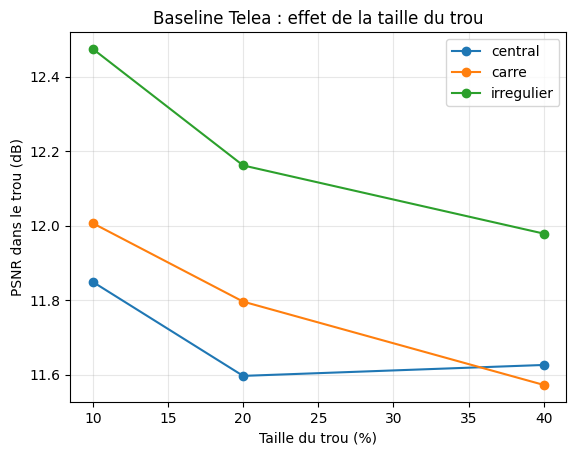

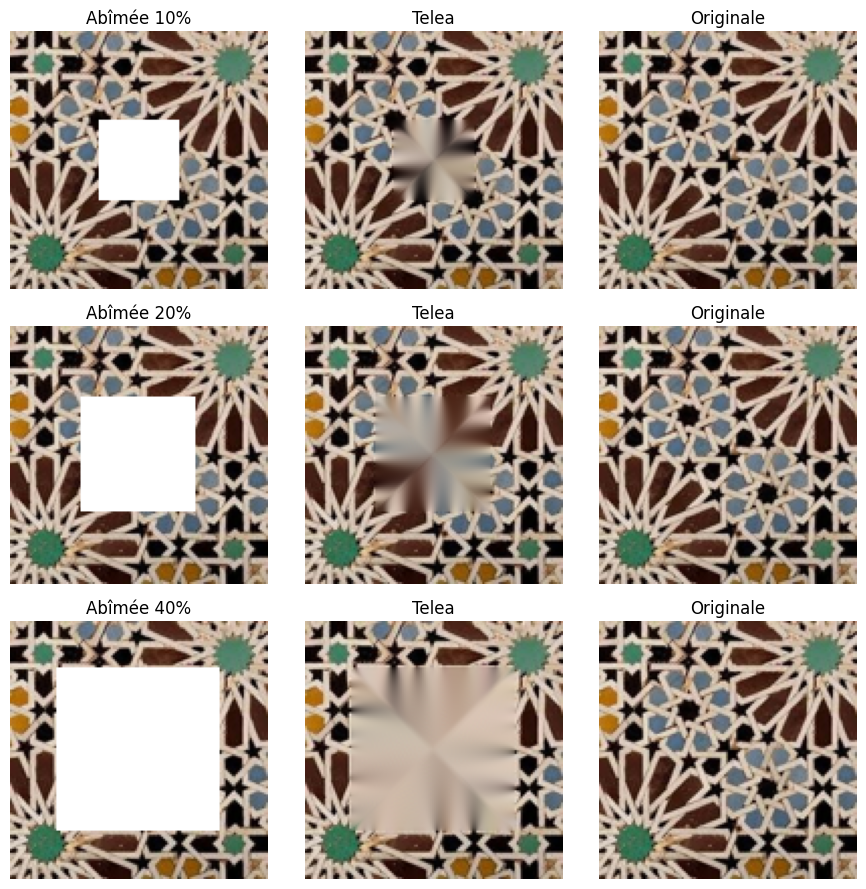

In [4]:
import matplotlib.pyplot as plt

# Graphique : PSNR en fonction de la taille du trou
for t in ["central", "carre", "irregulier"]:
    s = res[(res.methode == "telea") & (res.type == t)]
    plt.plot(s.trou, s.PSNR, marker="o", label=t)
plt.xlabel("Taille du trou (%)"); plt.ylabel("PSNR dans le trou (dB)")
plt.title("Baseline Telea : effet de la taille du trou"); plt.legend(); plt.grid(alpha=.3)
plt.show()

# Exemples : abîmée / restaurée / originale
i = 5
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for row, pct in enumerate([10, 20, 40]):
    m = M[f"central_{pct}"][i]
    abimee = X_test[i].copy(); abimee[m == 1] = 255
    rest = cv2.inpaint(X_test[i], m, 3, cv2.INPAINT_TELEA)
    for col, (im, titre) in enumerate([(abimee, f"Abîmée {pct}%"), (rest, "Telea"), (X_test[i], "Originale")]):
        axes[row, col].imshow(im); axes[row, col].set_title(titre); axes[row, col].axis("off")
plt.tight_layout(); plt.show()

In [5]:
for t in ["central", "carre", "irregulier"]:
    s = res[(res.methode == "telea") & (res.type == t)]
    plt.plot(s.trou, s.PSNR, marker="o", label=t)
plt.xlabel("Taille du trou (%)"); plt.ylabel("PSNR dans le trou (dB)")
plt.title("Baseline Telea : effet de la taille du trou"); plt.legend(); plt.grid(alpha=.3)
plt.savefig("/kaggle/working/baseline_psnr_taille.png", dpi=150, bbox_inches="tight"); plt.close()

i = 5
fig, axes = plt.subplots(3, 3, figsize=(9, 9))
for row, pct in enumerate([10, 20, 40]):
    m = M[f"central_{pct}"][i]
    abimee = X_test[i].copy(); abimee[m == 1] = 255
    rest = cv2.inpaint(X_test[i], m, 3, cv2.INPAINT_TELEA)
    for col, (im, titre) in enumerate([(abimee, f"Abîmée {pct}%"), (rest, "Telea"), (X_test[i], "Originale")]):
        axes[row, col].imshow(im); axes[row, col].set_title(titre); axes[row, col].axis("off")
plt.tight_layout()
plt.savefig("/kaggle/working/baseline_exemples.png", dpi=150, bbox_inches="tight"); plt.close()
print("Figures enregistrées ✔")

Figures enregistrées ✔
